# Part 1 — Data understanding and quality 

Rows: 921438
Columns: 39
Unique users: 50000
Date coverage: 2025-01-01 00:00:00 to 2026-07-01 00:00:00

Column names:
['userId', 'mes', 'oxxo_tx_ratio_m', 'oxxo_ratio_avg_prev3m', 'oxxo_ratio_delta_m', 'ecommerce_tx_ratio_m', 'virtual_card_ratio_m', 'intl_tx_ratio_m', 'tx_count_m', 'tx_amount_sum_m', 'tx_amount_avg_m', 'tx_count_delta_m', 'merchant_entropy_m', 'unique_mcc_m', 'cash_funding_ratio_m', 'spei_amount_m', 'spend_to_fund_ratio_m', 'decline_ratio_m', 'recovery_avg_min_m', 'next_month_observed', 'has_next_month', 'target_oxxo_migration', 'oxxo_ratio_change_next_m', 'target_ticket_growth', 'ticket_change_next_m', 'target_flip_out_30d', 'target_flip_in_liquidity_30d', 'target_flip_in_commercial_30d', 'target_reactivation_30d', 'month_num', 'tx_count_delta_m_was_missing', 'oxxo_ratio_delta_m_was_missing', 'oxxo_ratio_avg_prev3m_was_missing', 'is_zero_funding_m', 'had_decline_m', 'recovery_avg_min_m_was_missing', 'eligible_flip_out_m', 'eligible_flip_in_m', 'eligible_reactivation_m

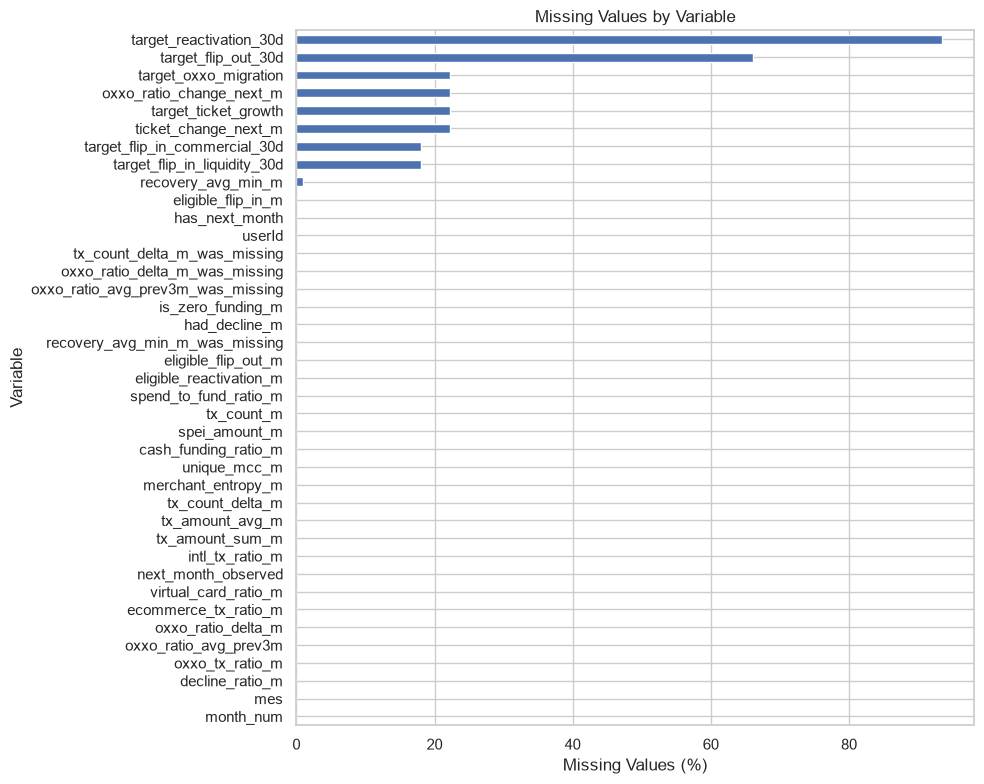


Duplicate user-month rows: 0

DESCRIPTIVE STATISTICS:
          tx_count_m  tx_amount_sum_m  tx_amount_avg_m  spei_amount_m
count  921438.000000    921438.000000    921438.000000  921438.000000
mean        9.869502      2382.181225       248.939559     585.525526
std        17.200182      5208.545320       483.826759    2778.109592
min         0.000000         0.000000         0.000000       0.000000
25%         1.000000       141.230000        52.456167       0.000000
50%         4.000000       797.895000       134.600000       0.000000
75%        12.000000      2589.705000       284.965632       4.090000
max      1137.000000    210873.040000     66547.700000  172435.270000

NEGATIVE VALUES:
tx_count_m : 0
tx_amount_sum_m : 0
tx_amount_avg_m : 0
spei_amount_m : 0

EXTREME VALUES:

 tx_amount_sum_m
0.01         0.0000
0.25       141.2300
0.50       797.8950
0.75      2589.7050
0.95      9585.3445
0.99     21708.1908
1.00    210873.0400
Name: tx_amount_sum_m, dtype: float64

 tx_amount

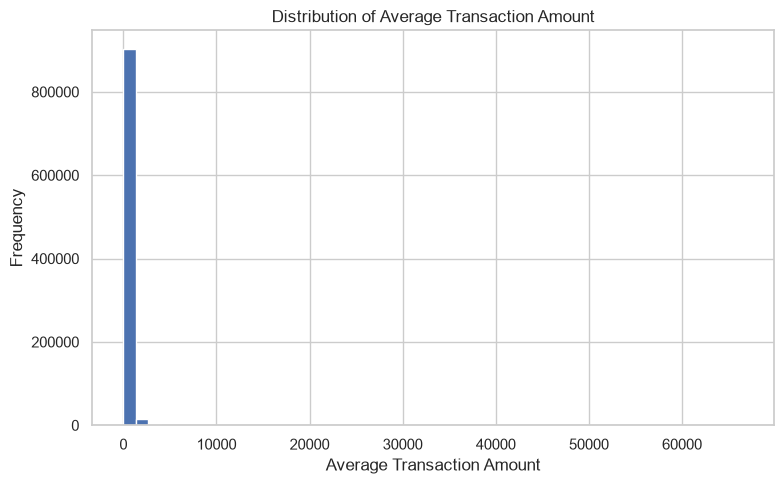


MONTHLY SUMMARY:
          mes  transactions        amount  active_users
0  2025-01-01        329132  8.420299e+07         42803
1  2025-02-01        332516  8.090741e+07         43957
2  2025-03-01        393080  9.435853e+07         45103
3  2025-04-01        404246  9.682559e+07         46118
4  2025-05-01        446238  1.074087e+08         47074
5  2025-06-01        445105  1.068294e+08         47931
6  2025-07-01        477880  1.137683e+08         48837
7  2025-08-01        508384  1.204906e+08         49615
8  2025-09-01        509011  1.169664e+08         50000
9  2025-10-01        543066  1.233551e+08         50000
10 2025-11-01        529846  1.308872e+08         50000
11 2025-12-01        545196  1.472010e+08         50000
12 2026-01-01        512976  1.279205e+08         50000
13 2026-02-01        487188  1.147796e+08         50000
14 2026-03-01        540687  1.266682e+08         50000
15 2026-04-01        517000  1.217637e+08         50000
16 2026-05-01        540136  1

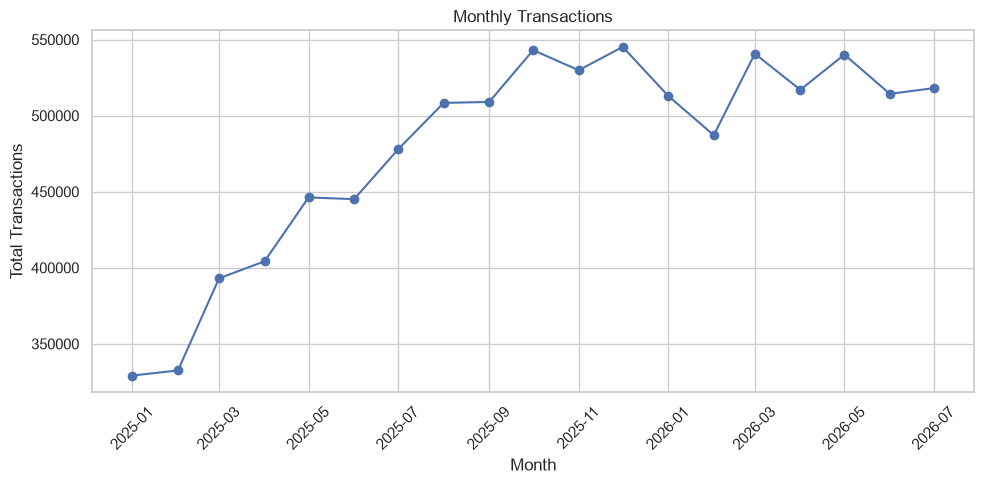

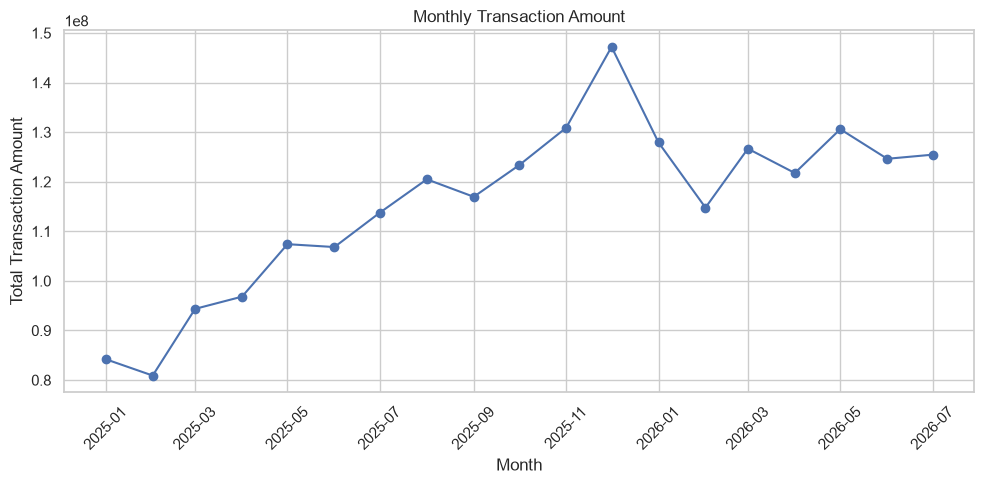

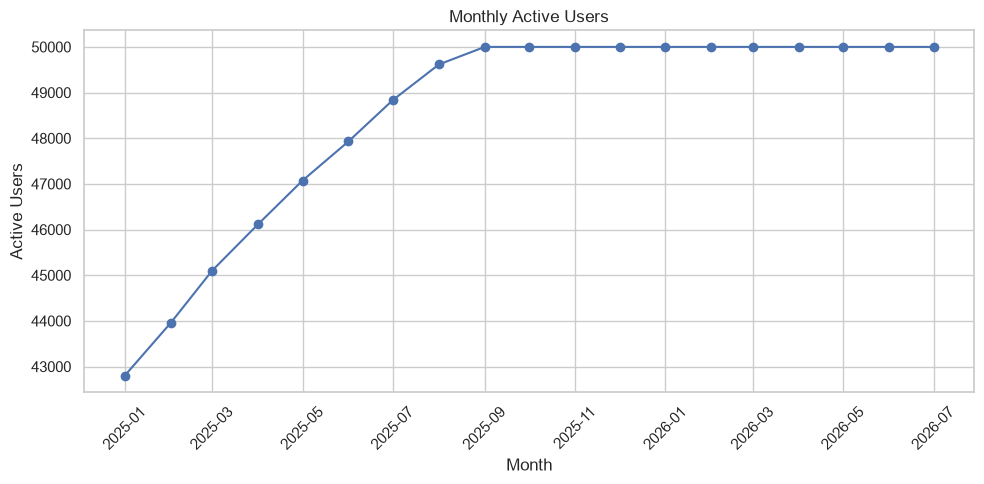


MONTH-TO-MONTH CHANGES:
          mes  transaction_change_pct  amount_change_pct  user_change_pct
0  2025-01-01                     NaN                NaN              NaN
1  2025-02-01                1.028159          -3.913845         2.696073
2  2025-03-01               18.213860          16.625319         2.607093
3  2025-04-01                2.840643           2.614556         2.250405
4  2025-05-01               10.387734          10.930058         2.072943
5  2025-06-01               -0.253900          -0.539343         1.820538
6  2025-07-01                7.363431           6.495309         1.890217
7  2025-08-01                6.383192           5.908802         1.593054
8  2025-09-01                0.123332          -2.924859         0.775975
9  2025-10-01                6.690425           5.461948         0.000000
10 2025-11-01               -2.434327           6.106011         0.000000
11 2025-12-01                2.897068          12.464071         0.000000
12 2026-01-01

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")



df = pd.read_csv("data/g5_dataSample_v2_processed.csv", parse_dates=["mes"])



# Basic dataset information
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Unique users:", df["userId"].nunique())
print("Date coverage:", df["mes"].min(), "to", df["mes"].max())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)




data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Type": [str(df[col].dtype) for col in df.columns],
    "Grain": ["User-month"] * len(df.columns),
    "Source": ["Spin by OXXO dataset"] * len(df.columns)
})

print("\nDATA DICTIONARY:")
print(data_dictionary)




missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing = missing.sort_values(
    by="Missing Percentage",
    ascending=False
)

print("\nMISSING VALUES:")
print(missing)


plt.figure(figsize=(10, 8))

missing["Missing Percentage"].sort_values().plot(
    kind="barh"
)

plt.title("Missing Values by Variable")
plt.xlabel("Missing Values (%)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()




duplicates = df.duplicated(
    subset=["userId", "mes"]
).sum()

print("\nDuplicate user-month rows:", duplicates)




numeric_cols = [
    "tx_count_m",
    "tx_amount_sum_m",
    "tx_amount_avg_m",
    "spei_amount_m"
]

print("\nDESCRIPTIVE STATISTICS:")
print(df[numeric_cols].describe())




print("\nNEGATIVE VALUES:")

for col in numeric_cols:
    negative_count = (df[col] < 0).sum()
    print(col, ":", negative_count)




print("\nEXTREME VALUES:")

for col in [
    "tx_amount_sum_m",
    "tx_amount_avg_m",
    "spei_amount_m"
]:
    print("\n", col)

    print(
        df[col].quantile(
            [0.01, 0.25, 0.50, 0.75, 0.95, 0.99, 1.00]
        )
    )




plt.figure(figsize=(8, 5))

plt.hist(
    df["tx_amount_avg_m"].dropna(),
    bins=50
)

plt.title("Distribution of Average Transaction Amount")
plt.xlabel("Average Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()




monthly = df.groupby("mes").agg(
    transactions=("tx_count_m", "sum"),
    amount=("tx_amount_sum_m", "sum"),
    active_users=("userId", "nunique")
).reset_index()

print("\nMONTHLY SUMMARY:")
print(monthly)




plt.figure(figsize=(10, 5))

plt.plot(
    monthly["mes"],
    monthly["transactions"],
    marker="o"
)

plt.title("Monthly Transactions")
plt.xlabel("Month")
plt.ylabel("Total Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




plt.figure(figsize=(10, 5))

plt.plot(
    monthly["mes"],
    monthly["amount"],
    marker="o"
)

plt.title("Monthly Transaction Amount")
plt.xlabel("Month")
plt.ylabel("Total Transaction Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




plt.figure(figsize=(10, 5))

plt.plot(
    monthly["mes"],
    monthly["active_users"],
    marker="o"
)

plt.title("Monthly Active Users")
plt.xlabel("Month")
plt.ylabel("Active Users")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




monthly["transaction_change_pct"] = (
    monthly["transactions"].pct_change() * 100
)

monthly["amount_change_pct"] = (
    monthly["amount"].pct_change() * 100
)

monthly["user_change_pct"] = (
    monthly["active_users"].pct_change() * 100
)

print("\nMONTH-TO-MONTH CHANGES:")

print(
    monthly[
        [
            "mes",
            "transaction_change_pct",
            "amount_change_pct",
            "user_change_pct"
        ]
    ]
)




monthly["possible_structural_break"] = (
    monthly["transaction_change_pct"].abs() > 30
)

print("\nPOSSIBLE STRUCTURAL BREAKS:")

print(
    monthly[
        monthly["possible_structural_break"] == True
    ]
)

# Part 3 — User features
Turn each user's many months into **one row per user** (a "profile"), look at how each feature behaves, remove repeated features, and check if users look like they form groups.


## 1. One row per user
We average each user's months. For ratios we only use months where the user actually made purchases (`tx_count_m > 0`), because a ratio with no purchases means nothing.

In [5]:
active = df[df.tx_count_m > 0]          # months with purchases
by_user = active.groupby("userId")
all_months = df.groupby("userId")

F = pd.DataFrame({
    # 1. OXXO dependency
    "oxxo_share":        by_user.oxxo_tx_ratio_m.mean(),
    # 2. Merchant diversity (entropy = how spread out purchases are across merchants)
    "merchant_entropy":  by_user.merchant_entropy_m.mean(),
    # 3. Channel and card mix
    "ecommerce_share":   by_user.ecommerce_tx_ratio_m.mean(),
    "virtual_card_share":by_user.virtual_card_ratio_m.mean(),
    "intl_share":        by_user.intl_tx_ratio_m.mean(),
    # 4. Habits over time (substitutes)
    "active_months_share": all_months.tx_count_m.apply(lambda s: (s > 0).mean()),   # how many months they buy
    "tx_variability":    all_months.tx_count_m.apply(lambda s: s.std() / s.mean() if s.mean() > 0 else np.nan),  # irregular = high
    # 5. Friction (declined payments)
    "decline_rate":      by_user.decline_ratio_m.mean(),
    "months_with_decline": all_months.had_decline_m.mean(),
    # extra: activity 
    "avg_ticket":        by_user.tx_amount_avg_m.mean(),
    "monthly_spend":     all_months.tx_amount_sum_m.mean(),
})
F.head()

,oxxo_share,merchant_entropy,ecommerce_share,virtual_card_share,intl_share,active_months_share,tx_variability,decline_rate,months_with_decline,avg_ticket,monthly_spend
userId,,,,,,,,,,,
SG5_000131a74409,0.481944,1.184773,0.000000,0.000000,0.000000,1.000000,0.503716,0.140972,0.500000,77.502104,501.187500
SG5_0003b71a5ba9,0.042206,1.233388,0.449297,0.000000,0.142229,1.000000,0.654097,0.411603,0.842105,186.133878,1042.160000
SG5_0003d78a5121,0.114341,1.131442,0.602661,0.000000,0.000000,1.000000,1.075415,0.039132,0.416667,306.098021,2113.634167
SG5_0003df2c9f4e,0.309858,1.625902,0.057204,0.057204,0.002024,1.000000,0.756658,0.240616,0.684211,157.437083,1966.561579
SG5_0005332ecd4e,0.097757,1.492589,0.517579,0.489376,0.000000,0.736842,1.214321,0.097024,0.368421,439.515144,1548.156316


## 2. Describe every feature
For each one: mean, median, spread (std), percentiles, **skewness** (0 = symmetric, big positive = long tail to the right), **kurtosis** (big = extreme values) and **% zeros**.

In [6]:
rows = []
for f in F.columns:
    x = F[f]
    rows.append({"feature": f, "mean": x.mean(), "median": x.median(), "std": x.std(),
                 "P1": x.quantile(.01), "P25": x.quantile(.25), "P75": x.quantile(.75), "P99": x.quantile(.99),
                 "skew": stats.skew(x), "kurtosis": stats.kurtosis(x), "% zeros": 100 * (x.abs() <= 0.001).mean()})
desc = pd.DataFrame(rows).set_index("feature").round(2)
desc

,mean,median,std,P1,P25,P75,P99,skew,kurtosis,% zeros
feature,,,,,,,,,,
oxxo_share,0.11,0.04,0.16,0.00,0.00,0.14,0.77,2.53,7.71,25.92
merchant_entropy,1.19,1.12,0.62,0.05,0.74,1.59,2.86,0.54,0.09,0.71
ecommerce_share,0.53,0.54,0.36,0.00,0.18,0.91,1.00,-0.09,-1.48,7.94
virtual_card_share,0.14,0.00,0.28,0.00,0.00,0.12,1.00,2.01,2.76,59.46
intl_share,0.14,0.04,0.20,0.00,0.00,0.19,0.88,1.95,3.58,31.16
active_months_share,0.85,0.89,0.14,0.58,0.74,1.00,1.00,-0.49,-1.07,0.00
tx_variability,0.88,0.85,0.33,0.27,0.64,1.08,1.78,0.63,1.15,0.12
decline_rate,0.26,0.20,0.21,0.00,0.08,0.39,0.80,0.82,-0.18,2.30
months_with_decline,0.57,0.58,0.29,0.00,0.33,0.83,1.00,-0.22,-1.06,1.99


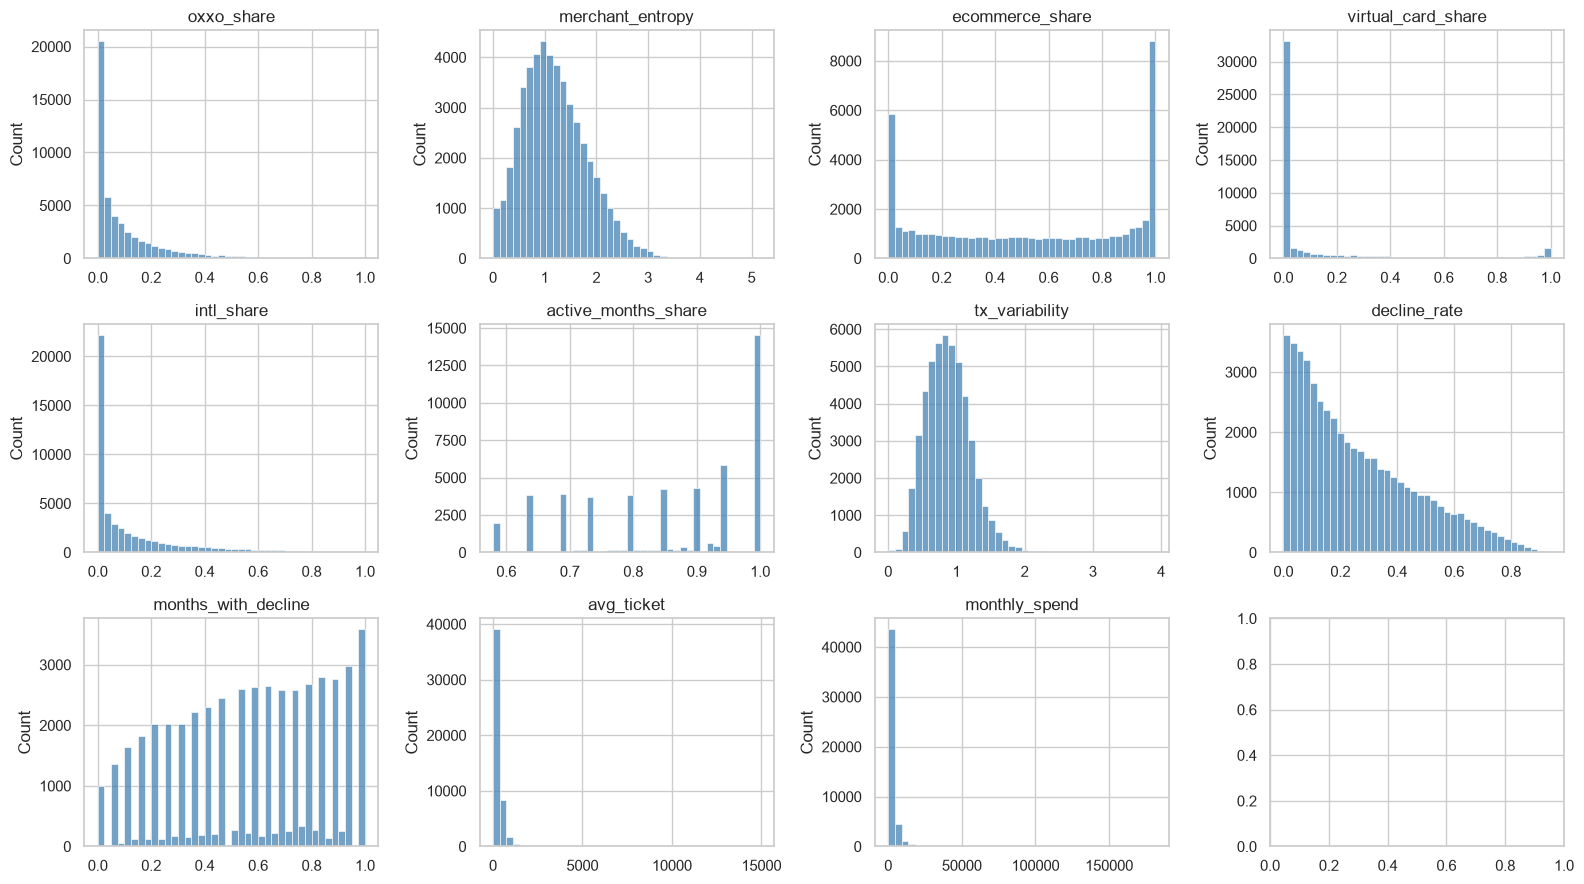

In [7]:
# Histogram of every feature
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, f in zip(axes.flat, F.columns):
    sns.histplot(F[f], bins=40, ax=ax, color="steelblue"); ax.set_title(f); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 3. Fix the very skewed features
Simple recipe: (a) **cap** values above the 99th percentile (winsorize) and (b) take `log(1 + x)` to shrink the long tail. Only for features with skew > 1.

Transformed: ['oxxo_share', 'virtual_card_share', 'intl_share', 'avg_ticket', 'monthly_spend']


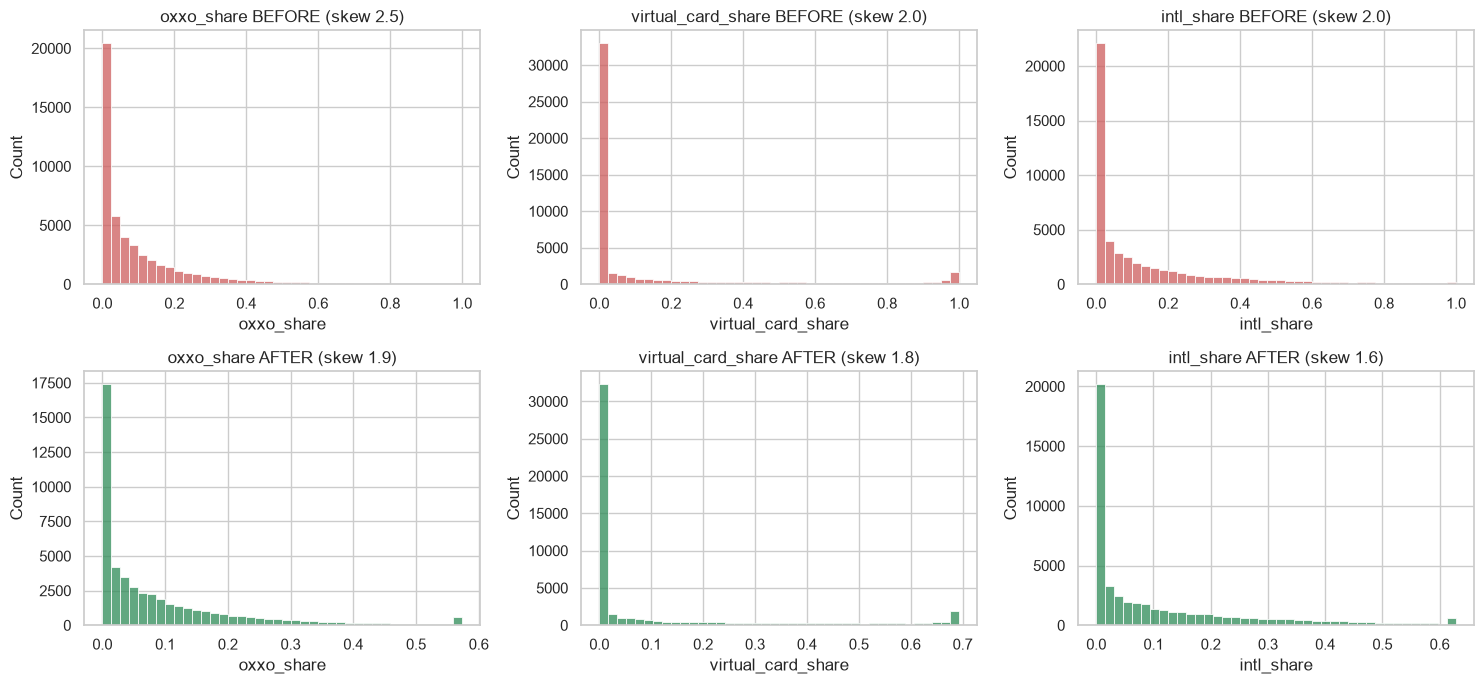

In [8]:
T = F.copy(); changed = []
for f in F.columns:
    if stats.skew(F[f]) > 1:
        T[f] = np.log1p(F[f].clip(upper=F[f].quantile(.99)))
        changed.append(f)
print("Transformed:", changed)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, f in enumerate(changed[:3]):
    sns.histplot(F[f], bins=40, ax=axes[0, i], color="indianred");  axes[0, i].set_title(f"{f} BEFORE (skew {stats.skew(F[f]):.1f})")
    sns.histplot(T[f], bins=40, ax=axes[1, i], color="seagreen");   axes[1, i].set_title(f"{f} AFTER (skew {stats.skew(T[f]):.1f})")
plt.tight_layout(); plt.show()

## 4. Features with no information
A feature where almost everyone has the same value cannot separate users. Rule: drop it if > 90% zeros.

In [9]:
null_summary = pd.DataFrame({
    "n_null": df.isna().sum(),
    "pct_null": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
})
useless = null_summary[null_summary["pct_null"] > 90].index.tolist()
print("No-information features:", useless if useless else "none in this table")


No-information features: ['target_reactivation_30d']


## 5. Repeated information (correlation)
From the complete dataset: Two features that move together tell the same story. We use **Spearman** correlation (works with skewed data). Close to +1/−1 = repeated.

17 candidate features for correlation / clustering:
['oxxo_tx_ratio_m', 'oxxo_ratio_avg_prev3m', 'oxxo_ratio_delta_m', 'ecommerce_tx_ratio_m', 'virtual_card_ratio_m', 'intl_tx_ratio_m', 'tx_count_m', 'tx_amount_sum_m', 'tx_amount_avg_m', 'tx_count_delta_m', 'merchant_entropy_m', 'unique_mcc_m', 'cash_funding_ratio_m', 'spei_amount_m', 'spend_to_fund_ratio_m', 'decline_ratio_m', 'recovery_avg_min_m']

2 redundant pairs (|Spearman rho| >= 0.90):
  +0.940   merchant_entropy_m  <->  unique_mcc_m
  +0.927   decline_ratio_m  <->  recovery_avg_min_m


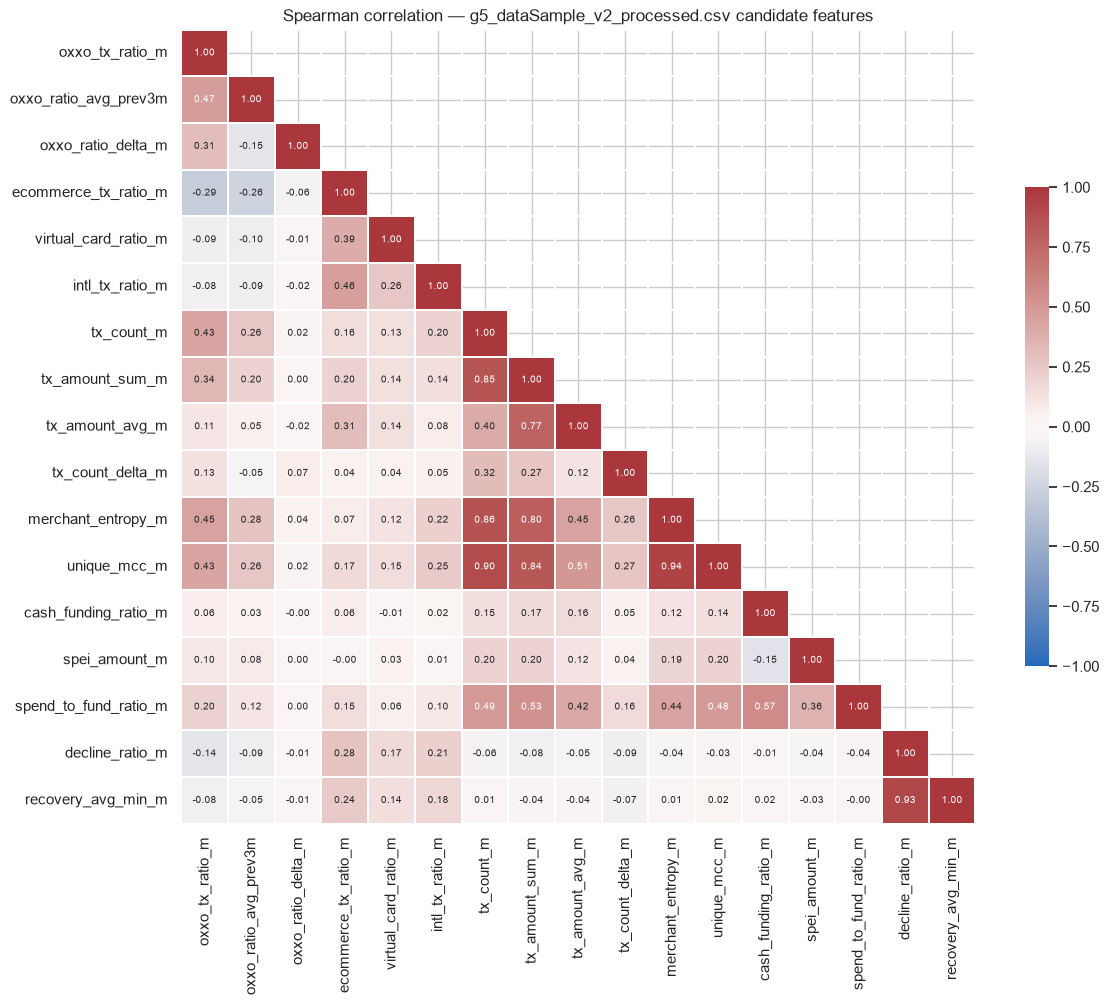

In [10]:
exclude_patterns = ("_was_missing", "target_", "_next_m")
exclude_exact = {
    "userId", "mes", "month_num", "next_month_observed", "has_next_month",
    "is_zero_funding_m", "had_decline_m",
    "eligible_flip_out_m", "eligible_flip_in_m", "eligible_reactivation_m",
}

feature_cols = [
    c for c in df.select_dtypes(include=[np.number]).columns
    if c not in exclude_exact and not any(p in c for p in exclude_patterns)
]

num = df[feature_cols]
num = num.loc[:, num.nunique() > 1]
print(f"{num.shape[1]} candidate features for correlation / clustering:")
print(list(num.columns))

corr = num.corr("spearman")
cols = corr.columns
redundant = [
    (cols[i], cols[j], corr.iloc[i, j])
    for i in range(len(cols)) for j in range(i + 1, len(cols))
    if abs(corr.iloc[i, j]) >= 0.90
]
redundant.sort(key=lambda t: -abs(t[2]))

print(f"\n{len(redundant)} redundant pairs (|Spearman rho| >= 0.90):")
for a, b, r in redundant:
    print(f"  {r:+.3f}   {a}  <->  {b}")

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            xticklabels=True, yticklabels=True, linewidths=.3,
            cbar_kws={"shrink": .6}, ax=ax)
ax.set_title("Spearman correlation — g5_dataSample_v2_processed.csv candidate features")
plt.tight_layout()
plt.show()

Only the feature table same idea: Two features that move together tell the same story. We use **Spearman** correlation (works with skewed data). Close to +1/−1 = repeated.

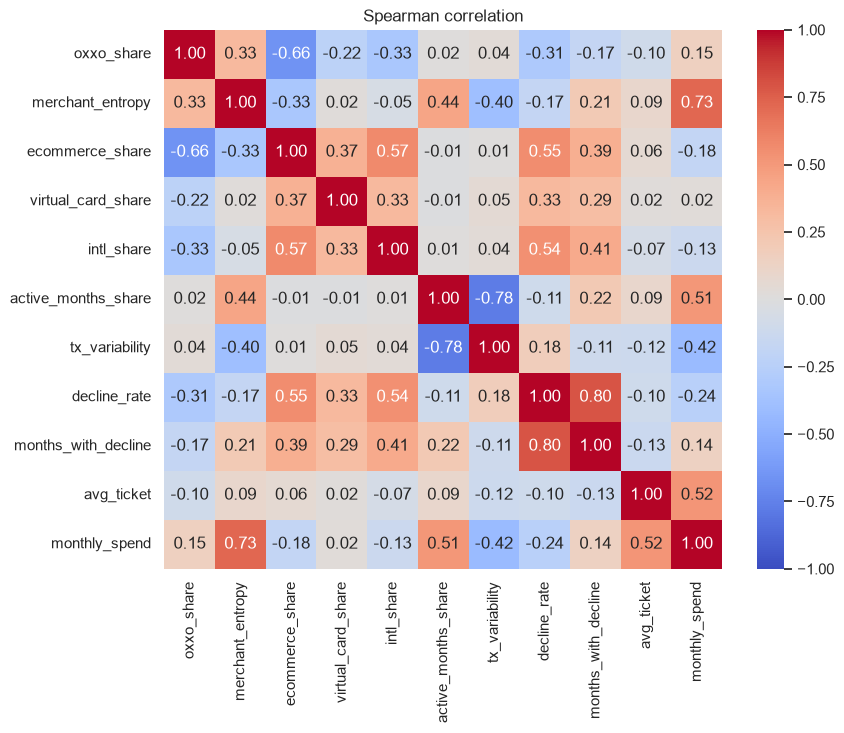

[('merchant_entropy', 'monthly_spend', np.float64(0.73)),
 ('active_months_share', 'tx_variability', np.float64(-0.78)),
 ('decline_rate', 'months_with_decline', np.float64(0.8))]

In [11]:
corr = T.corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation"); plt.show()

# list the pairs that are too similar (|corr| >= 0.7)
pairs = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns) for b in corr.columns[i+1:] if abs(corr.loc[a, b]) >= 0.7]
pairs

In [12]:
# Simple rule: from each too-similar pair, drop the second one
to_drop = ['months_with_decline']

keep = [f for f in F.columns if f not in to_drop and f not in useless]
print("Dropped:", sorted(to_drop)); print("Keep:", keep)

Dropped: ['months_with_decline']
Keep: ['oxxo_share', 'merchant_entropy', 'ecommerce_share', 'virtual_card_share', 'intl_share', 'active_months_share', 'tx_variability', 'decline_rate', 'avg_ticket', 'monthly_spend']


## 6. Feature readiness table

In [13]:
ready = pd.DataFrame({
    "Feature": F.columns,
    "% missing": 0.0,   # missing values were filled in step 1 (only a few users)
    "Skewness": [round(stats.skew(F[f]), 2) for f in F.columns],
    "Transformation": ["cap P99 + log" if f in changed else "none" for f in F.columns],
    "Keep/Drop": ["Keep" if f in keep else "Drop" for f in F.columns],
    "Justification": [("repeats another feature (corr >= 0.7)" if f in to_drop else "no information" if f in useless else "adds its own information") for f in F.columns]})
ready

,Feature,% missing,Skewness,Transformation,Keep/Drop,Justification
0,oxxo_share,0.0,2.53,cap P99 + log,Keep,adds its own information
1,merchant_entropy,0.0,0.54,none,Keep,adds its own information
2,ecommerce_share,0.0,-0.09,none,Keep,adds its own information
3,virtual_card_share,0.0,2.01,cap P99 + log,Keep,adds its own information
4,intl_share,0.0,1.95,cap P99 + log,Keep,adds its own information
5,active_months_share,0.0,-0.49,none,Keep,adds its own information
6,tx_variability,0.0,0.63,none,Keep,adds its own information
7,decline_rate,0.0,0.82,none,Keep,adds its own information
8,months_with_decline,0.0,-0.22,none,Drop,repeats another feature (corr >= 0.7)
9,avg_ticket,0.0,7.95,cap P99 + log,Keep,adds its own information


## 7. Do users form natural groups?
Three simple checks.

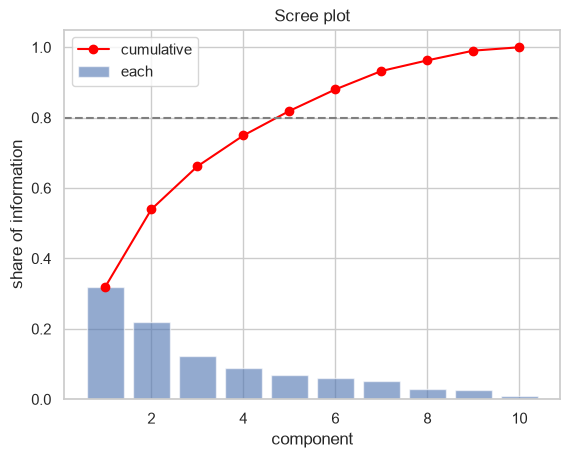

Components needed for 80%: 5


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

Z = StandardScaler().fit_transform(T[keep])     # put all features on the same scale

# (a) PCA "scree": how many combined features do we need to keep most of the information?
pca = PCA().fit(Z); cum = pca.explained_variance_ratio_.cumsum()
plt.bar(range(1, len(cum)+1), pca.explained_variance_ratio_, alpha=.6, label="each")
plt.plot(range(1, len(cum)+1), cum, "o-", color="red", label="cumulative"); plt.axhline(.8, ls="--", color="grey")
plt.xlabel("component"); plt.ylabel("share of information"); plt.legend(); plt.title("Scree plot"); plt.show()
print("Components needed for 80%:", int((cum >= .8).argmax() + 1))

In [15]:
# (b) Hopkins statistic: ~0.5 = no groups (random), close to 1 = clear groups
rng = np.random.default_rng(0)
def hopkins(X, m=1000):
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    real = X[rng.choice(len(X), m, replace=False)]
    d_real = nn.kneighbors(real, 2)[0][:, 1]                          # distance to nearest OTHER real user
    fake = rng.uniform(X.min(0), X.max(0), (m, X.shape[1]))            # random points
    d_fake = nn.kneighbors(fake, 1)[0][:, 0]
    return d_fake.sum() / (d_fake.sum() + d_real.sum())
print("Hopkins:", round(hopkins(Z), 3))

Hopkins: 0.875


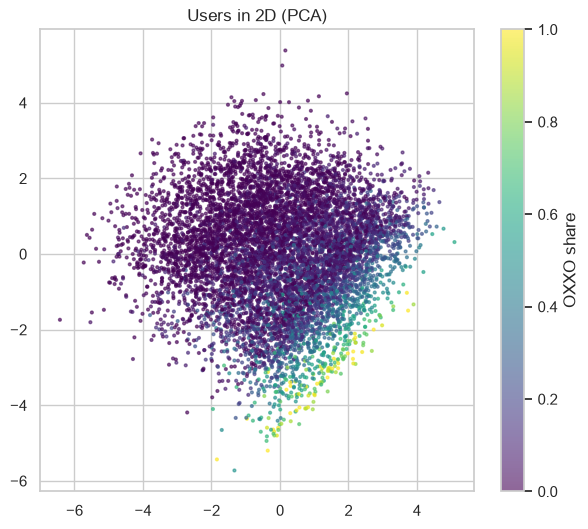

In [16]:
# (c) 2D picture: squash all features into 2 axes (PCA) and colour by OXXO share
P = PCA(2).fit_transform(Z); s = rng.choice(len(Z), 8000, replace=False)
plt.figure(figsize=(7, 6)); sc = plt.scatter(P[s, 0], P[s, 1], c=F.oxxo_share.values[s], s=4, cmap="viridis", alpha=.6)
plt.colorbar(sc, label="OXXO share"); plt.title("Users in 2D (PCA)"); plt.show()

**How to read it:** the scree plot says how many dimensions the behaviour really has; Hopkins above ~0.75 means users are not spread randomly (groups likely); in the 2D picture, look for separate clouds.

## 8. OXXO share

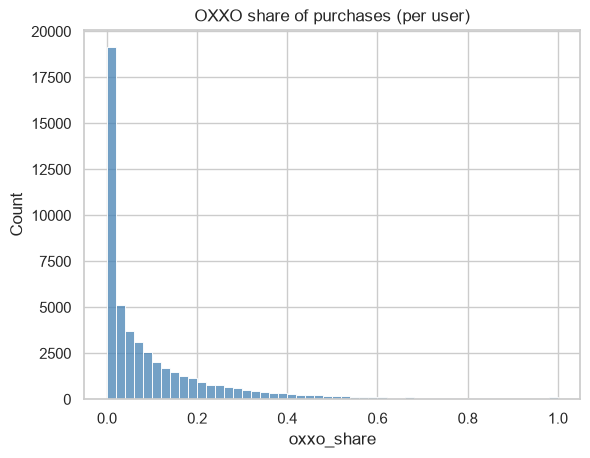

exactly 0: 25.8%   |   <= 1%: 31.7%   |   >= 99%: 0.2%   |   > 50%: 3.7%


In [17]:
o = F.oxxo_share
sns.histplot(o, bins=50, color="steelblue"); plt.title("OXXO share of purchases (per user)"); plt.show()
print(f"exactly 0: {(o==0).mean()*100:.1f}%   |   <= 1%: {(o<=.01).mean()*100:.1f}%   |   >= 99%: {(o>=.99).mean()*100:.1f}%   |   > 50%: {(o>.5).mean()*100:.1f}%")

**Read:** a big pile at 0 (many users never use OXXO), a tail to the right, almost nobody at 1. It is not two separate humps; it is 'zero for many, a little for most, a lot for a few'.

## 9. Compare groups of users
No account level / age / gender here, so we split users into **low / mid / high spenders** (thirds of monthly spend) and compare.

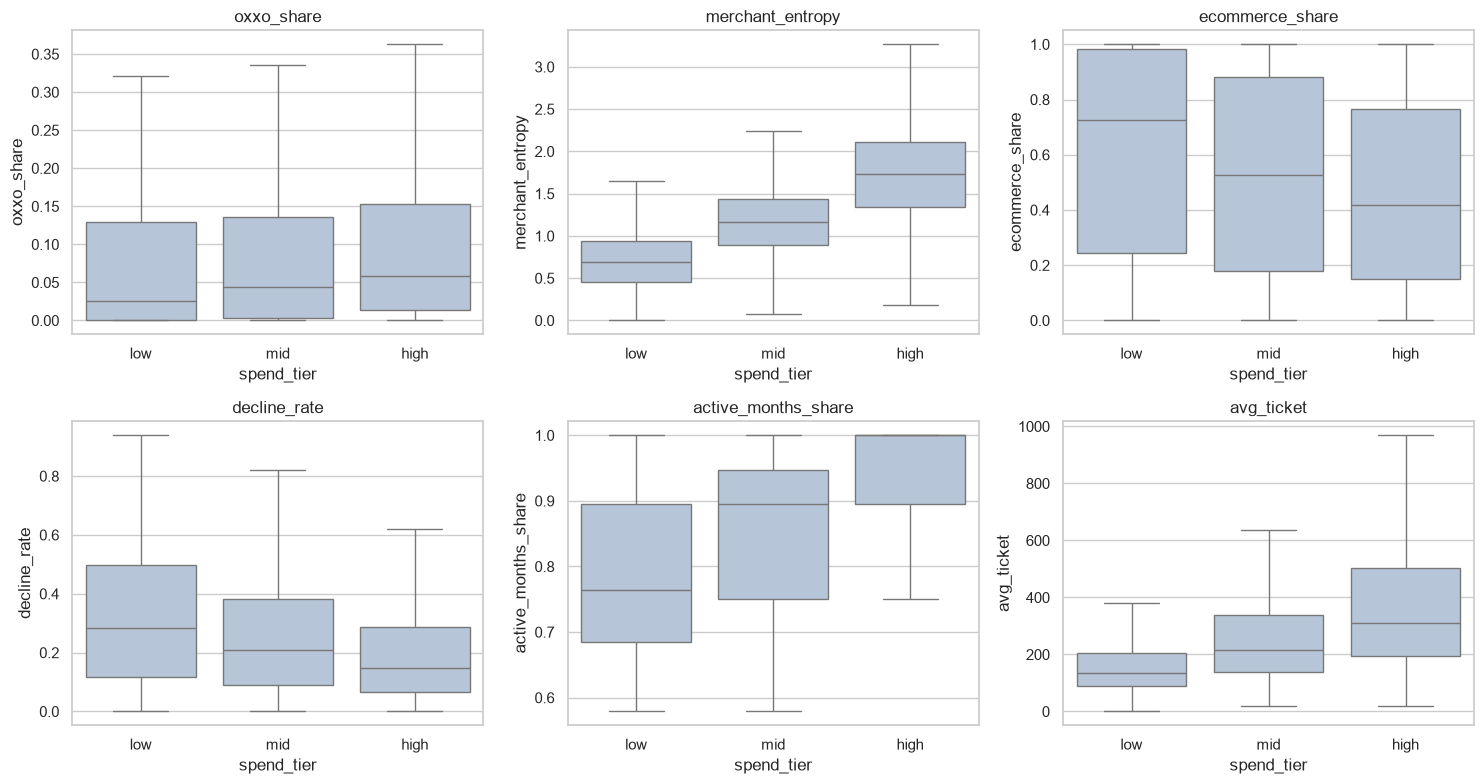

,oxxo_share,merchant_entropy,ecommerce_share,decline_rate
spend_tier,,,,
low,0.026,0.696,0.726,0.285
mid,0.044,1.164,0.528,0.210
high,0.059,1.729,0.419,0.149


In [18]:
F["spend_tier"] = pd.qcut(F.monthly_spend, 3, labels=["low", "mid", "high"])
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.flat, ["oxxo_share", "merchant_entropy", "ecommerce_share", "decline_rate", "active_months_share", "avg_ticket"]):
    sns.boxplot(data=F, x="spend_tier", y=f, ax=ax, showfliers=False, color="lightsteelblue"); ax.set_title(f)
plt.tight_layout(); plt.show()
F.groupby("spend_tier", observed=True)[["oxxo_share", "merchant_entropy", "ecommerce_share", "decline_rate"]].median().round(3)

## 10. Would the groups last over time?
Simple check: split the months into the first half and the second half, rebuild a few features, and compare.

In [19]:
mid = df.mes.min() + (df.mes.max() - df.mes.min()) / 2
def quick(d):
    a = d[d.tx_count_m > 0].groupby("userId")
    return pd.DataFrame({"oxxo_share": a.oxxo_tx_ratio_m.mean(), "ecommerce_share": a.ecommerce_tx_ratio_m.mean(),
                         "merchant_entropy": a.merchant_entropy_m.mean(), "decline_rate": a.decline_ratio_m.mean()})
A, B = quick(df[df.mes <= mid]), quick(df[df.mes > mid])
both = A.join(B, lsuffix="_1st", rsuffix="_2nd", how="inner").dropna()
out = pd.DataFrame({"median 1st half": A.median(), "median 2nd half": B.median(),
                    "same user, 1st vs 2nd (corr)": [both[f"{c}_1st"].corr(both[f"{c}_2nd"], method="spearman") for c in A.columns]}).round(2)
out

,median 1st half,median 2nd half,"same user, 1st vs 2nd (corr)"
oxxo_share,0.04,0.03,0.69
ecommerce_share,0.50,0.58,0.84
merchant_entropy,1.07,1.13,0.64
decline_rate,0.17,0.22,0.66


**Read:** medians almost equal = the population looks the same over time. A high correlation (close to 1) = each user behaves similarly in both halves, so groups based on that feature should last. Low = that behaviour changes a lot.

# Part 5 — User features

In [20]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)

df = pd.read_csv("data/g5_dataSample_v2_processed.csv", parse_dates=["mes"])


active = df[df.tx_count_m > 0]
by_user, all_months = active.groupby("userId"), df.groupby("userId")
F = pd.DataFrame({
    "oxxo_share":          by_user.oxxo_tx_ratio_m.mean(),
    "merchant_entropy":    by_user.merchant_entropy_m.mean(),
    "ecommerce_share":     by_user.ecommerce_tx_ratio_m.mean(),
    "virtual_card_share":  by_user.virtual_card_ratio_m.mean(),
    "intl_share":          by_user.intl_tx_ratio_m.mean(),
    "active_months_share": all_months.tx_count_m.apply(lambda s: (s > 0).mean()),
    "tx_variability":      all_months.tx_count_m.apply(lambda s: s.std() / s.mean() if s.mean() > 0 else np.nan),
    "decline_rate":        by_user.decline_ratio_m.mean(),
    "months_with_decline": all_months.had_decline_m.mean(),
    "avg_ticket":          by_user.tx_amount_avg_m.mean(),
    "monthly_spend":       all_months.tx_amount_sum_m.mean(),
})
FEATURES = [c for c in F.columns if c != "months_with_decline"]  


GROUP = "spend_tier"
F[GROUP] = pd.qcut(F.monthly_spend, 3, labels=["low", "mid", "high"])

TARGETS = {"Flip-Out": "target_flip_out_30d", "Flip-In": "target_flip_in_liquidity_30d"}
FLIP_RATE_CUT, MIN_ELIGIBLE = 0.5, 3      
flip_rate = {}
for name, col in TARGETS.items():
    g = df[df[col].notna()].groupby("userId")[col].agg(["mean", "count"])
    g = g[g["count"] >= MIN_ELIGIBLE]
    flip_rate[name] = g["mean"]
    F[name] = (g["mean"] >= FLIP_RATE_CUT).astype(float)      # NaN = not enough eligible months

print(f"{len(df):,} user-months | {len(F):,} users | {F.oxxo_share.notna().sum():,} users with purchases")
print(F[GROUP].value_counts().to_dict())
for name in TARGETS:
    print(f"{name}: {F[name].notna().sum():,} users with >= {MIN_ELIGIBLE} eligible months, {F[name].mean()*100:.1f}% are flippers")

# Sensitivity of the flipper definition to the cut-off
pd.DataFrame({name: {f"rate >= {c}": (r >= c).mean() for c in (.25, .34, .5, .75)} for name, r in flip_rate.items()}).round(3)

921,438 user-months | 50,000 users | 50,000 users with purchases
{'low': 16667, 'high': 16667, 'mid': 16666}
Flip-Out: 35,714 users with >= 3 eligible months, 34.4% are flippers
Flip-In: 49,727 users with >= 3 eligible months, 59.4% are flippers


,Flip-Out,Flip-In
rate >= 0.25,0.722,0.761
rate >= 0.34,0.501,0.689
rate >= 0.5,0.344,0.594
rate >= 0.75,0.107,0.387


## 1. Confidence intervals (95%)
- **Means** (OXXO share, decline rate): analytical t-interval, plus a bootstrap check.
- **Proportions** (target prevalence): Wilson interval (better than the usual formula when the proportion is near 0 or 1).
- Groups are `spend_tier`. An interval that does not overlap another one is a quick sign of a real difference.

In [21]:
def mean_ci(x, conf=.95):
    x = x.dropna(); n = len(x); m = x.mean()
    h = stats.t.ppf((1 + conf) / 2, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return n, m, m - h, m + h

def wilson_ci(x, conf=.95):
    x = x.dropna(); n = len(x); p = x.mean(); z = stats.norm.ppf((1 + conf) / 2)
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return n, p, centre - half, centre + half

groups = {"Overall": F, **{g: d for g, d in F.groupby(GROUP, observed=True)}}
rows = []
for gname, d in groups.items():
    for metric in ["oxxo_share", "decline_rate"]:
        n, est, lo, hi = mean_ci(d[metric]); rows.append((metric, gname, n, est, lo, hi))
    for name in TARGETS:
        n, est, lo, hi = wilson_ci(d[name]); rows.append((f"{name} prevalence", gname, n, est, lo, hi))
ci = pd.DataFrame(rows, columns=["metric", "group", "n", "estimate", "ci_low", "ci_high"])
ci["half_width"] = (ci.ci_high - ci.ci_low) / 2
ci.round(4)

,metric,group,n,estimate,ci_low,ci_high,half_width
0,oxxo_share,Overall,50000,0.1062,0.1048,0.1076,0.0014
1,decline_rate,Overall,50000,0.2568,0.2550,0.2586,0.0018
2,Flip-Out prevalence,Overall,35714,0.3439,0.3390,0.3488,0.0049
3,Flip-In prevalence,Overall,49727,0.5942,0.5898,0.5985,0.0043
4,oxxo_share,low,16667,0.1089,0.1060,0.1117,0.0029
5,decline_rate,low,16667,0.3207,0.3172,0.3242,0.0035
6,Flip-Out prevalence,low,16056,0.2463,0.2397,0.2531,0.0067
7,Flip-In prevalence,low,16453,0.5090,0.5014,0.5167,0.0076
8,oxxo_share,mid,16666,0.1019,0.0996,0.1041,0.0022
9,decline_rate,mid,16666,0.2535,0.2505,0.2565,0.0030


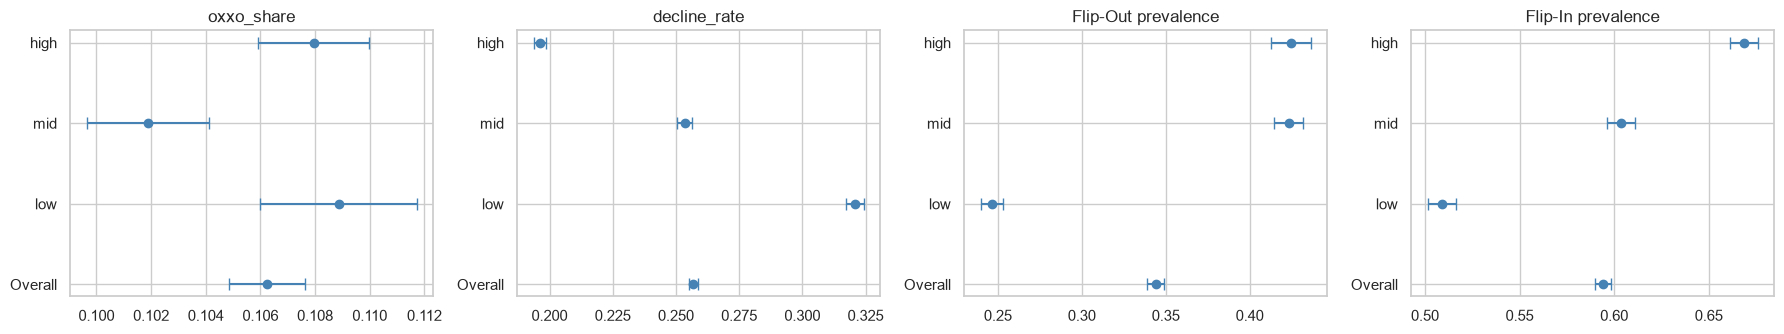

In [22]:
# Forest plot: estimate and 95% CI per group
metrics = ci.metric.unique()
fig, axes = plt.subplots(1, len(metrics), figsize=(4.5 * len(metrics), 3.5))
for ax, m in zip(axes, metrics):
    d = ci[ci.metric == m].reset_index(drop=True)
    ax.errorbar(d.estimate, range(len(d)), xerr=[d.estimate - d.ci_low, d.ci_high - d.estimate],
                fmt="o", color="steelblue", capsize=4)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d.group); ax.set_title(m)
plt.tight_layout(); plt.show()

In [23]:
# Bootstrap check 
def boot_mean_ci(x, n_boot=2000):
    x = x.dropna().values
    means = np.array([rng.choice(x, len(x)).mean() for _ in range(n_boot)])
    return np.percentile(means, [2.5, 97.5])

chk = []
for metric in ["oxxo_share", "decline_rate"]:
    _, _, lo, hi = mean_ci(F[metric]); blo, bhi = boot_mean_ci(F[metric])
    chk.append((metric, lo, hi, blo, bhi))
pd.DataFrame(chk, columns=["metric", "analytical_low", "analytical_high", "bootstrap_low", "bootstrap_high"]).round(4)

,metric,analytical_low,analytical_high,bootstrap_low,bootstrap_high
0,oxxo_share,0.1048,0.1076,0.1048,0.1076
1,decline_rate,0.2550,0.2586,0.2550,0.2586


In [24]:
# Target prevalence over USER-MONTHS with a cluster bootstrap 
def cluster_boot_prev(col, users=None, n_boot=1000):
    d = df if users is None else df[df.userId.isin(users)]
    g = d[d[col].notna()].groupby("userId")[col].agg(["sum", "count"])
    s, c = g["sum"].values, g["count"].values
    prev = []
    for _ in range(n_boot):
        i = rng.integers(0, len(g), len(g)); prev.append(s[i].sum() / c[i].sum())
    return s.sum() / c.sum(), *np.percentile(prev, [2.5, 97.5])

rows = []
for name, col in TARGETS.items():
    for gname, d in groups.items():
        est, lo, hi = cluster_boot_prev(col, None if gname == "Overall" else d.index)
        rows.append((name, gname, est, lo, hi))
pd.DataFrame(rows, columns=["target", "group", "prevalence (user-months)", "ci_low", "ci_high"]).round(4)

,target,group,prevalence (user-months),ci_low,ci_high
0,Flip-Out,Overall,0.3473,0.3451,0.3496
1,Flip-Out,low,0.2924,0.2896,0.2955
2,Flip-Out,mid,0.4009,0.3968,0.4048
3,Flip-Out,high,0.4324,0.4267,0.4383
4,Flip-In,Overall,0.5708,0.5677,0.5739
5,Flip-In,low,0.4908,0.4857,0.4963
6,Flip-In,mid,0.5724,0.5670,0.5775
7,Flip-In,high,0.6337,0.6289,0.6390


## 2. One-way ANOVA: OXXO share across groups

            count   mean  median    std
spend_tier                             
low         16667  0.109   0.026  0.188
mid         16666  0.102   0.044  0.147
high        16667  0.108   0.059  0.134 

Shapiro-Wilk [low]: W = 0.620, p = 2.66e-74, skew = 2.58
Shapiro-Wilk [mid]: W = 0.707, p = 4.86e-69, skew = 2.41
Shapiro-Wilk [high]: W = 0.769, p = 2.23e-64, skew = 2.10


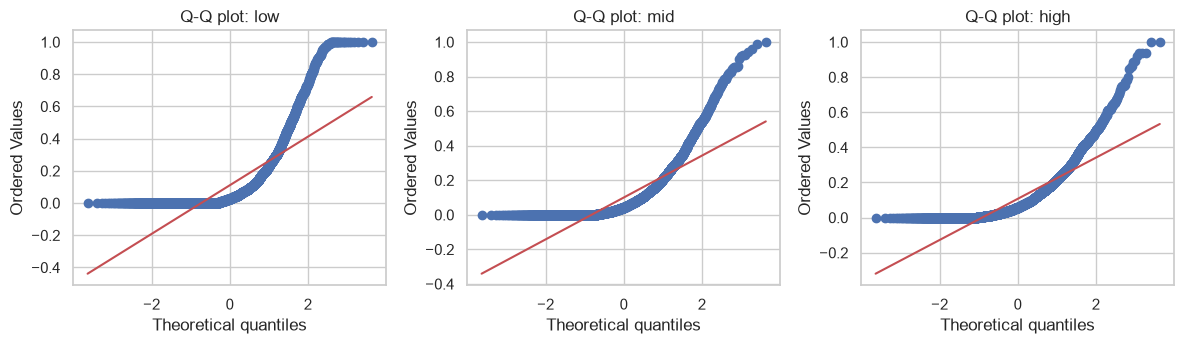


Levene: stat = 65.27, p = 4.91e-29


In [25]:
data = F.dropna(subset=["oxxo_share", GROUP])
labels = list(data.groupby(GROUP, observed=True).groups.keys())
samples = [data.loc[data[GROUP] == g, "oxxo_share"].values for g in labels]
N = len(data)

print(data.groupby(GROUP, observed=True).oxxo_share.agg(["count", "mean", "median", "std"]).round(3), "\n")

# (a) Normality
for g, s in zip(labels, samples):
    W, p = stats.shapiro(rng.choice(s, min(5000, len(s)), replace=False))
    print(f"Shapiro-Wilk [{g}]: W = {W:.3f}, p = {p:.2e}, skew = {stats.skew(s):.2f}")
fig, axes = plt.subplots(1, len(labels), figsize=(4 * len(labels), 3.6))
for ax, g, s in zip(axes, labels, samples):
    stats.probplot(rng.choice(s, min(5000, len(s)), replace=False), dist="norm", plot=ax); ax.set_title(f"Q-Q plot: {g}")
plt.tight_layout(); plt.show()

# (b) Equal variances: Levene 
lev = stats.levene(*samples, center="median")
print(f"\nLevene: stat = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")

In [26]:
# ANOVA + effect size 
f_stat, p_anova = stats.f_oneway(*samples)
grand = data.oxxo_share.mean()
ss_between = sum(len(s) * (s.mean() - grand) ** 2 for s in samples)
ss_total = ((data.oxxo_share - grand) ** 2).sum()
eta2 = ss_between / ss_total
print(f"ANOVA: F = {f_stat:.1f}, p = {p_anova:.2e}, eta^2 = {eta2:.4f}")

# Kruskal-Wallis + effect size 
H, p_kw = stats.kruskal(*samples)
eps2 = H * (N + 1) / (N ** 2 - 1)
print(f"Kruskal-Wallis: H = {H:.1f}, p = {p_kw:.2e}, epsilon^2 = {eps2:.4f}")

def size_label(v, cuts=(.01, .06, .14)):
    return "negligible" if v < cuts[0] else "small" if v < cuts[1] else "medium" if v < cuts[2] else "large"
print(f"Practical size (eta^2 rule 0.01 / 0.06 / 0.14): {size_label(eta2)}")

ANOVA: F = 9.6, p = 6.67e-05, eta^2 = 0.0004
Kruskal-Wallis: H = 908.8, p = 4.44e-198, epsilon^2 = 0.0182
Practical size (eta^2 rule 0.01 / 0.06 / 0.14): negligible


In [27]:
# Post-hoc: pairwise Mann-Whitney with Bonferroni correction + Cliff's delta (effect size, -1 to 1)
from itertools import combinations
def cliff_delta(a, b):
    U = stats.mannwhitneyu(a, b, alternative="two-sided").statistic
    return 2 * U / (len(a) * len(b)) - 1          

pairs = list(combinations(range(len(labels)), 2)); post = []
for i, j in pairs:
    p = stats.mannwhitneyu(samples[i], samples[j], alternative="two-sided").pvalue
    d = cliff_delta(samples[i], samples[j])
    post.append((f"{labels[i]} vs {labels[j]}", np.median(samples[i]), np.median(samples[j]),
                 min(p * len(pairs), 1), d,
                 "negligible" if abs(d) < .147 else "small" if abs(d) < .33 else "medium" if abs(d) < .474 else "large"))
pd.DataFrame(post, columns=["pair", "median_1", "median_2", "p_bonferroni", "cliffs_delta", "size"]).round(4)

,pair,median_1,median_2,p_bonferroni,cliffs_delta,size
0,low vs mid,0.0256,0.0439,0.0,-0.1008,negligible
1,low vs high,0.0256,0.0588,0.0,-0.1871,small
2,mid vs high,0.0439,0.0588,0.0,-0.0918,negligible


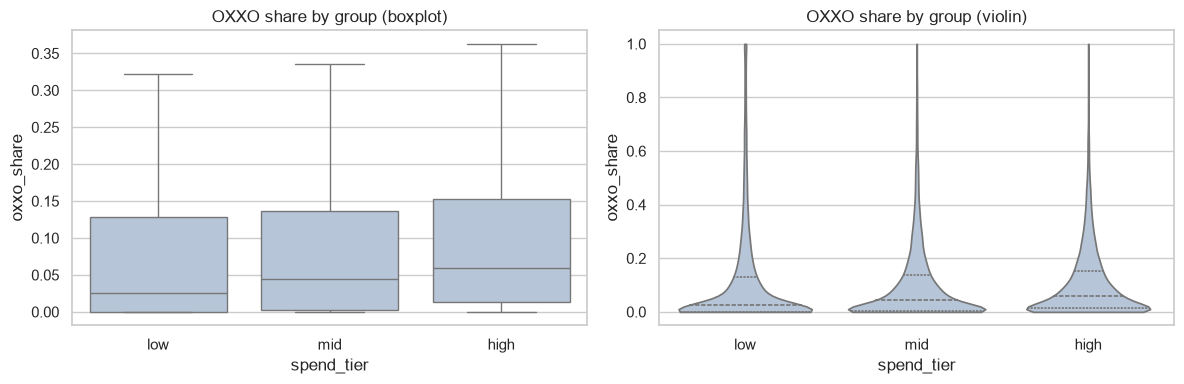

In [28]:
# Picture of the groups
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=data, x=GROUP, y="oxxo_share", ax=axes[0], showfliers=False, color="lightsteelblue")
axes[0].set_title("OXXO share by group (boxplot)")
sns.violinplot(data=data, x=GROUP, y="oxxo_share", ax=axes[1], cut=0, inner="quartile", color="lightsteelblue")
axes[1].set_title("OXXO share by group (violin)")
plt.tight_layout(); plt.show()

## 3. Flippers vs non-flippers
Flippers = users who flipped in at least `FLIP_RATE_CUT` of their eligible months. Numeric features: **Mann-Whitney U** (no normality needed) with the **rank-biserial correlation** as effect size (same scale as Cliff's delta; positive = flippers have higher values). Categorical features: **chi-square** with **Cramér's V**. p-values are Bonferroni-corrected across features.

In [29]:
F["oxxo_profile"] = pd.cut(F.oxxo_share, [-.001, 0, .5, 1], labels=["no OXXO", "mixed (0-0.5]", "dependent (>0.5)"])
F["any_decline"] = np.where(F.months_with_decline.notna(), (F.months_with_decline > 0).map({True: "yes", False: "no"}), np.nan)
CATEGORICAL = [GROUP, "oxxo_profile", "any_decline"]

def label_d(d): return "negligible" if abs(d) < .147 else "small" if abs(d) < .33 else "medium" if abs(d) < .474 else "large"

num_results, cat_results = {}, {}
for tname in TARGETS:
    d = F[F[tname].notna()]
    # numeric: Mann-Whitney U
    rows = []
    for f in FEATURES:
        a, b = d.loc[d[tname] == 1, f].dropna(), d.loc[d[tname] == 0, f].dropna()
        U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        r = 2 * U / (len(a) * len(b)) - 1
        rows.append((f, a.median(), b.median(), U, min(p * len(FEATURES), 1), r, label_d(r)))
    num_results[tname] = pd.DataFrame(rows, columns=["feature", "median_flippers", "median_non", "U", "p_bonferroni", "rank_biserial", "size"]) \
        .sort_values("rank_biserial", key=abs, ascending=False).set_index("feature")
    # categorical: chi-square
    rows = []
    for f in CATEGORICAL:
        tab = pd.crosstab(d[f], d[tname])
        chi2, p, dof, _ = stats.chi2_contingency(tab)
        v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
        rows.append((f, chi2, dof, min(p * len(CATEGORICAL), 1), v,
                     "negligible" if v < .1 else "small" if v < .3 else "medium" if v < .5 else "large"))
    cat_results[tname] = pd.DataFrame(rows, columns=["feature", "chi2", "dof", "p_bonferroni", "cramers_v", "size"]).set_index("feature")
    print(f"=== {tname}: {int(d[tname].sum()):,} flippers vs {int((d[tname] == 0).sum()):,} non-flippers ===")
    display(num_results[tname].round(4)); display(cat_results[tname].round(4))

=== Flip-Out: 12,282 flippers vs 23,432 non-flippers ===


,median_flippers,median_non,U,p_bonferroni,rank_biserial,size
feature,,,,,,
active_months_share,0.8947,0.7368,229510454.5,0.0000,0.5950,large
tx_variability,0.8468,1.0393,86644139.5,0.0000,-0.3979,medium
merchant_entropy,1.0402,0.8208,182902056.5,0.0000,0.2711,small
monthly_spend,1143.9705,763.0766,179309877.0,0.0000,0.2461,small
avg_ticket,210.0060,189.8910,154082978.0,0.0000,0.0708,negligible
ecommerce_share,0.5429,0.5927,138354827.0,0.0000,-0.0385,negligible
intl_share,0.0476,0.0394,147032595.5,0.0054,0.0218,negligible
oxxo_share,0.0421,0.0417,143346180.5,1.0000,-0.0038,negligible
decline_rate,0.2232,0.2277,143619899.0,1.0000,-0.0019,negligible


,chi2,dof,p_bonferroni,cramers_v,size
feature,,,,,
spend_tier,1230.8629,2,0.0,0.1856,small
oxxo_profile,477.9126,2,0.0,0.1157,small
any_decline,22.9205,1,0.0,0.0253,negligible


=== Flip-In: 29,546 flippers vs 20,181 non-flippers ===


,median_flippers,median_non,U,p_bonferroni,rank_biserial,size
feature,,,,,,
monthly_spend,1468.4525,1052.9374,348069145.0,0.0,0.1675,small
avg_ticket,218.3300,189.8165,329372158.0,0.0,0.1048,negligible
merchant_entropy,1.1745,1.0568,327960846.0,0.0,0.1000,negligible
active_months_share,0.8947,0.8421,327362139.5,0.0,0.0980,negligible
virtual_card_share,0.0000,0.0000,273788814.0,0.0,-0.0817,negligible
intl_share,0.0353,0.0564,273907578.0,0.0,-0.0813,negligible
tx_variability,0.8339,0.8859,274373532.5,0.0,-0.0797,negligible
oxxo_share,0.0478,0.0351,317944666.0,0.0,0.0664,negligible
ecommerce_share,0.5165,0.5893,278835629.0,0.0,-0.0647,negligible


,chi2,dof,p_bonferroni,cramers_v,size
feature,,,,,
spend_tier,884.0496,2,0.0,0.1333,small
oxxo_profile,228.8584,2,0.0,0.0678,negligible
any_decline,23.6874,1,0.0,0.0218,negligible


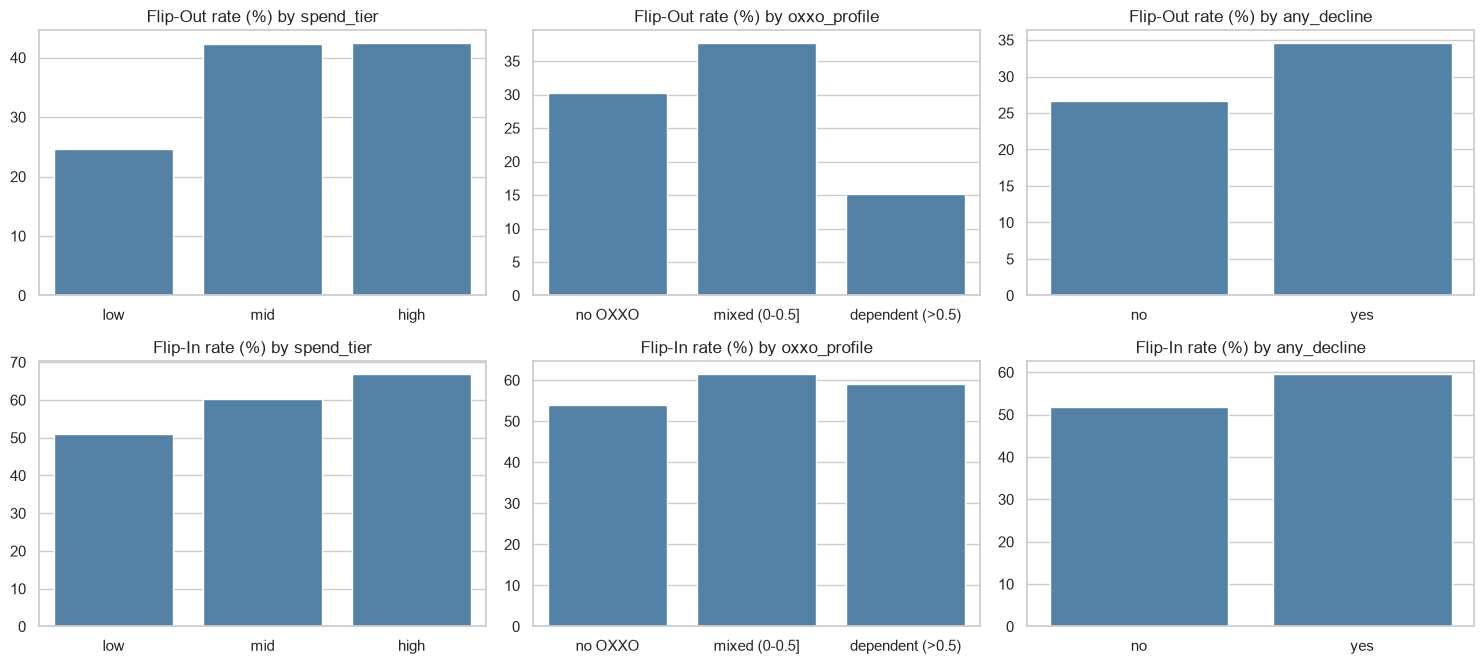

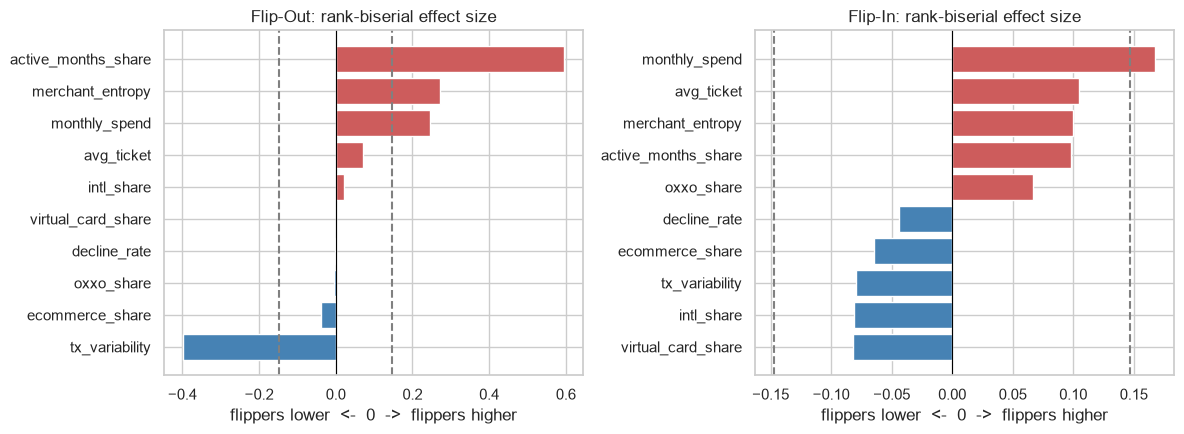

In [30]:
# Flip rate by category (what the chi-square compares)
fig, axes = plt.subplots(len(TARGETS), len(CATEGORICAL), figsize=(5 * len(CATEGORICAL), 3.4 * len(TARGETS)))
for r, tname in enumerate(TARGETS):
    for c, f in enumerate(CATEGORICAL):
        rate = F[F[tname].notna()].groupby(f, observed=True)[tname].mean() * 100
        sns.barplot(x=rate.index.astype(str), y=rate.values, ax=axes[r, c], color="steelblue")
        axes[r, c].set_title(f"{tname} rate (%) by {f}"); axes[r, c].set_xlabel("")
plt.tight_layout(); plt.show()

# Effect sizes of the numeric features (practical significance)
fig, axes = plt.subplots(1, len(TARGETS), figsize=(6 * len(TARGETS), 4.5))
for ax, tname in zip(axes, TARGETS):
    e = num_results[tname].rank_biserial.sort_values()
    ax.barh(e.index, e.values, color=np.where(e.values > 0, "indianred", "steelblue"))
    for x in (-.147, .147): ax.axvline(x, ls="--", color="grey")
    ax.axvline(0, color="black", lw=.8); ax.set_title(f"{tname}: rank-biserial effect size"); ax.set_xlabel("flippers lower  <-  0  ->  flippers higher")
plt.tight_layout(); plt.show()

## Results 
**Confidence intervals.** OXXO share averages 0.106 (95% CI 0.105-0.108) and the decline rate 0.257 (0.255-0.259). Declines fall clearly with spend (low 32.1%, mid 25.4%, high 19.6%; intervals do not overlap). OXXO share has a similar mean in all tiers (0.109 / 0.102 / 0.108). Frequent flippers: 34.4% for Flip-Out (33.9-34.9%) and 59.4% for Flip-In (59.0-59.9%); both rise with spend tier (Flip-In: 50.9% -> 60.4% -> 66.9%). Flip-Out eligibility differs a lot by tier (high spenders are less often eligible), so compare those rates with care.

**ANOVA.** The normality (Shapiro p < 1e-60, skew 2.1-2.6) and equal-variance (Levene p < 1e-28) assumptions fail, so ANOVA is not reliable here. It is significant (F = 9.6, p < 0.001) but with a negligible effect (eta^2 = 0.0004): the *means* are almost the same. Kruskal-Wallis, which compares whole distributions, is strongly significant (H = 909, epsilon^2 = 0.018) and the *medians* differ (0.026 low, 0.044 mid, 0.059 high). Post-hoc: only low vs high is a small effect (Cliff's delta = -0.19); the other pairs are negligible. In short: high spenders use OXXO a bit more in the typical case, but the tiers do not separate OXXO dependence in a practically important way.

**Flippers vs non-flippers.** Flip-Out: the largest differences are in activity (`active_months_share`, r = 0.60, large; flippers buy in more months) and regularity (`tx_variability`, r = -0.40, medium; flippers are more regular), then `merchant_entropy` and `monthly_spend` (small). `oxxo_share`, `decline_rate` and `virtual_card_share` do not differ. Flip-In: only `monthly_spend` reaches a small effect (r = 0.17); the rest are negligible. Among categorical variables, `spend_tier` has a small association with both targets (Cramer's V 0.19 and 0.13) and `any_decline` a negligible one.